# 5. Assess — PDF §7.5, páginas 9–10

Evaluación de modelos congelados con datos retenidos. Métricas binarias y multietiqueta, matrices 2×2 por etiqueta, errores y comparación con un clasificador trivial.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
assert (ROOT / 'src').is_dir(), 'Abrir desde avance_semma o su carpeta notebooks'
sys.path.insert(0, str(ROOT))
import pandas as pd
from IPython.display import display, Image, Markdown


In [2]:
from src.experiment import assess
comparison = assess()
display(pd.DataFrame(comparison))
selection = json.loads((ROOT / 'results/model_selection.json').read_text(encoding='utf-8'))
family = selection['family']
display(pd.read_csv(ROOT / f'results/{family}_por_categoria.csv'))

             family      candidate  threshold  train_category_f1_macro  validation_category_f1_macro  test_binary_precision  test_binary_recall  test_binary_f1  test_category_precision_macro  test_category_recall_macro  test_category_f1_macro  test_category_f1_micro  test_hamming_loss  test_subset_accuracy
      random_forest rf_150_depth20        0.3                 0.888438                      0.845987               0.771689            1.000000        0.871134                       0.709612                    1.000000                0.804025                0.918206           0.009091              0.914956
logistic_regression          lr_C2        0.5                 0.838527                      0.625509               0.867403            0.928994        0.897143                       0.633846                    0.662628                0.639136                0.821429           0.017595              0.832845


,family,candidate,threshold,train_category_f1_macro,validation_category_f1_macro,test_binary_precision,test_binary_recall,test_binary_f1,test_category_precision_macro,test_category_recall_macro,test_category_f1_macro,test_category_f1_micro,test_hamming_loss,test_subset_accuracy
0,random_forest,rf_150_depth20,0.3,0.888438,0.845987,0.771689,1.000000,0.871134,0.709612,1.000000,0.804025,0.918206,0.009091,0.914956
1,logistic_regression,lr_C2,0.5,0.838527,0.625509,0.867403,0.928994,0.897143,0.633846,0.662628,0.639136,0.821429,0.017595,0.832845


,categoria,precision,recall,f1-score,support
0,A01:2025,0.904762,1.000000,0.950000,19.0
1,A02:2025,0.500000,1.000000,0.666667,1.0
2,A04:2025,1.000000,1.000000,1.000000,9.0
3,A05:2025,0.858025,1.000000,0.923588,139.0
4,A07:2025,0.500000,1.000000,0.666667,1.0
5,API1:2023,1.000000,1.000000,1.000000,1.0
6,API2:2023,0.500000,1.000000,0.666667,1.0
7,API3:2023,0.333333,1.000000,0.500000,1.0
8,API5:2023,0.500000,1.000000,0.666667,1.0
9,API8:2023,1.000000,1.000000,1.000000,1.0


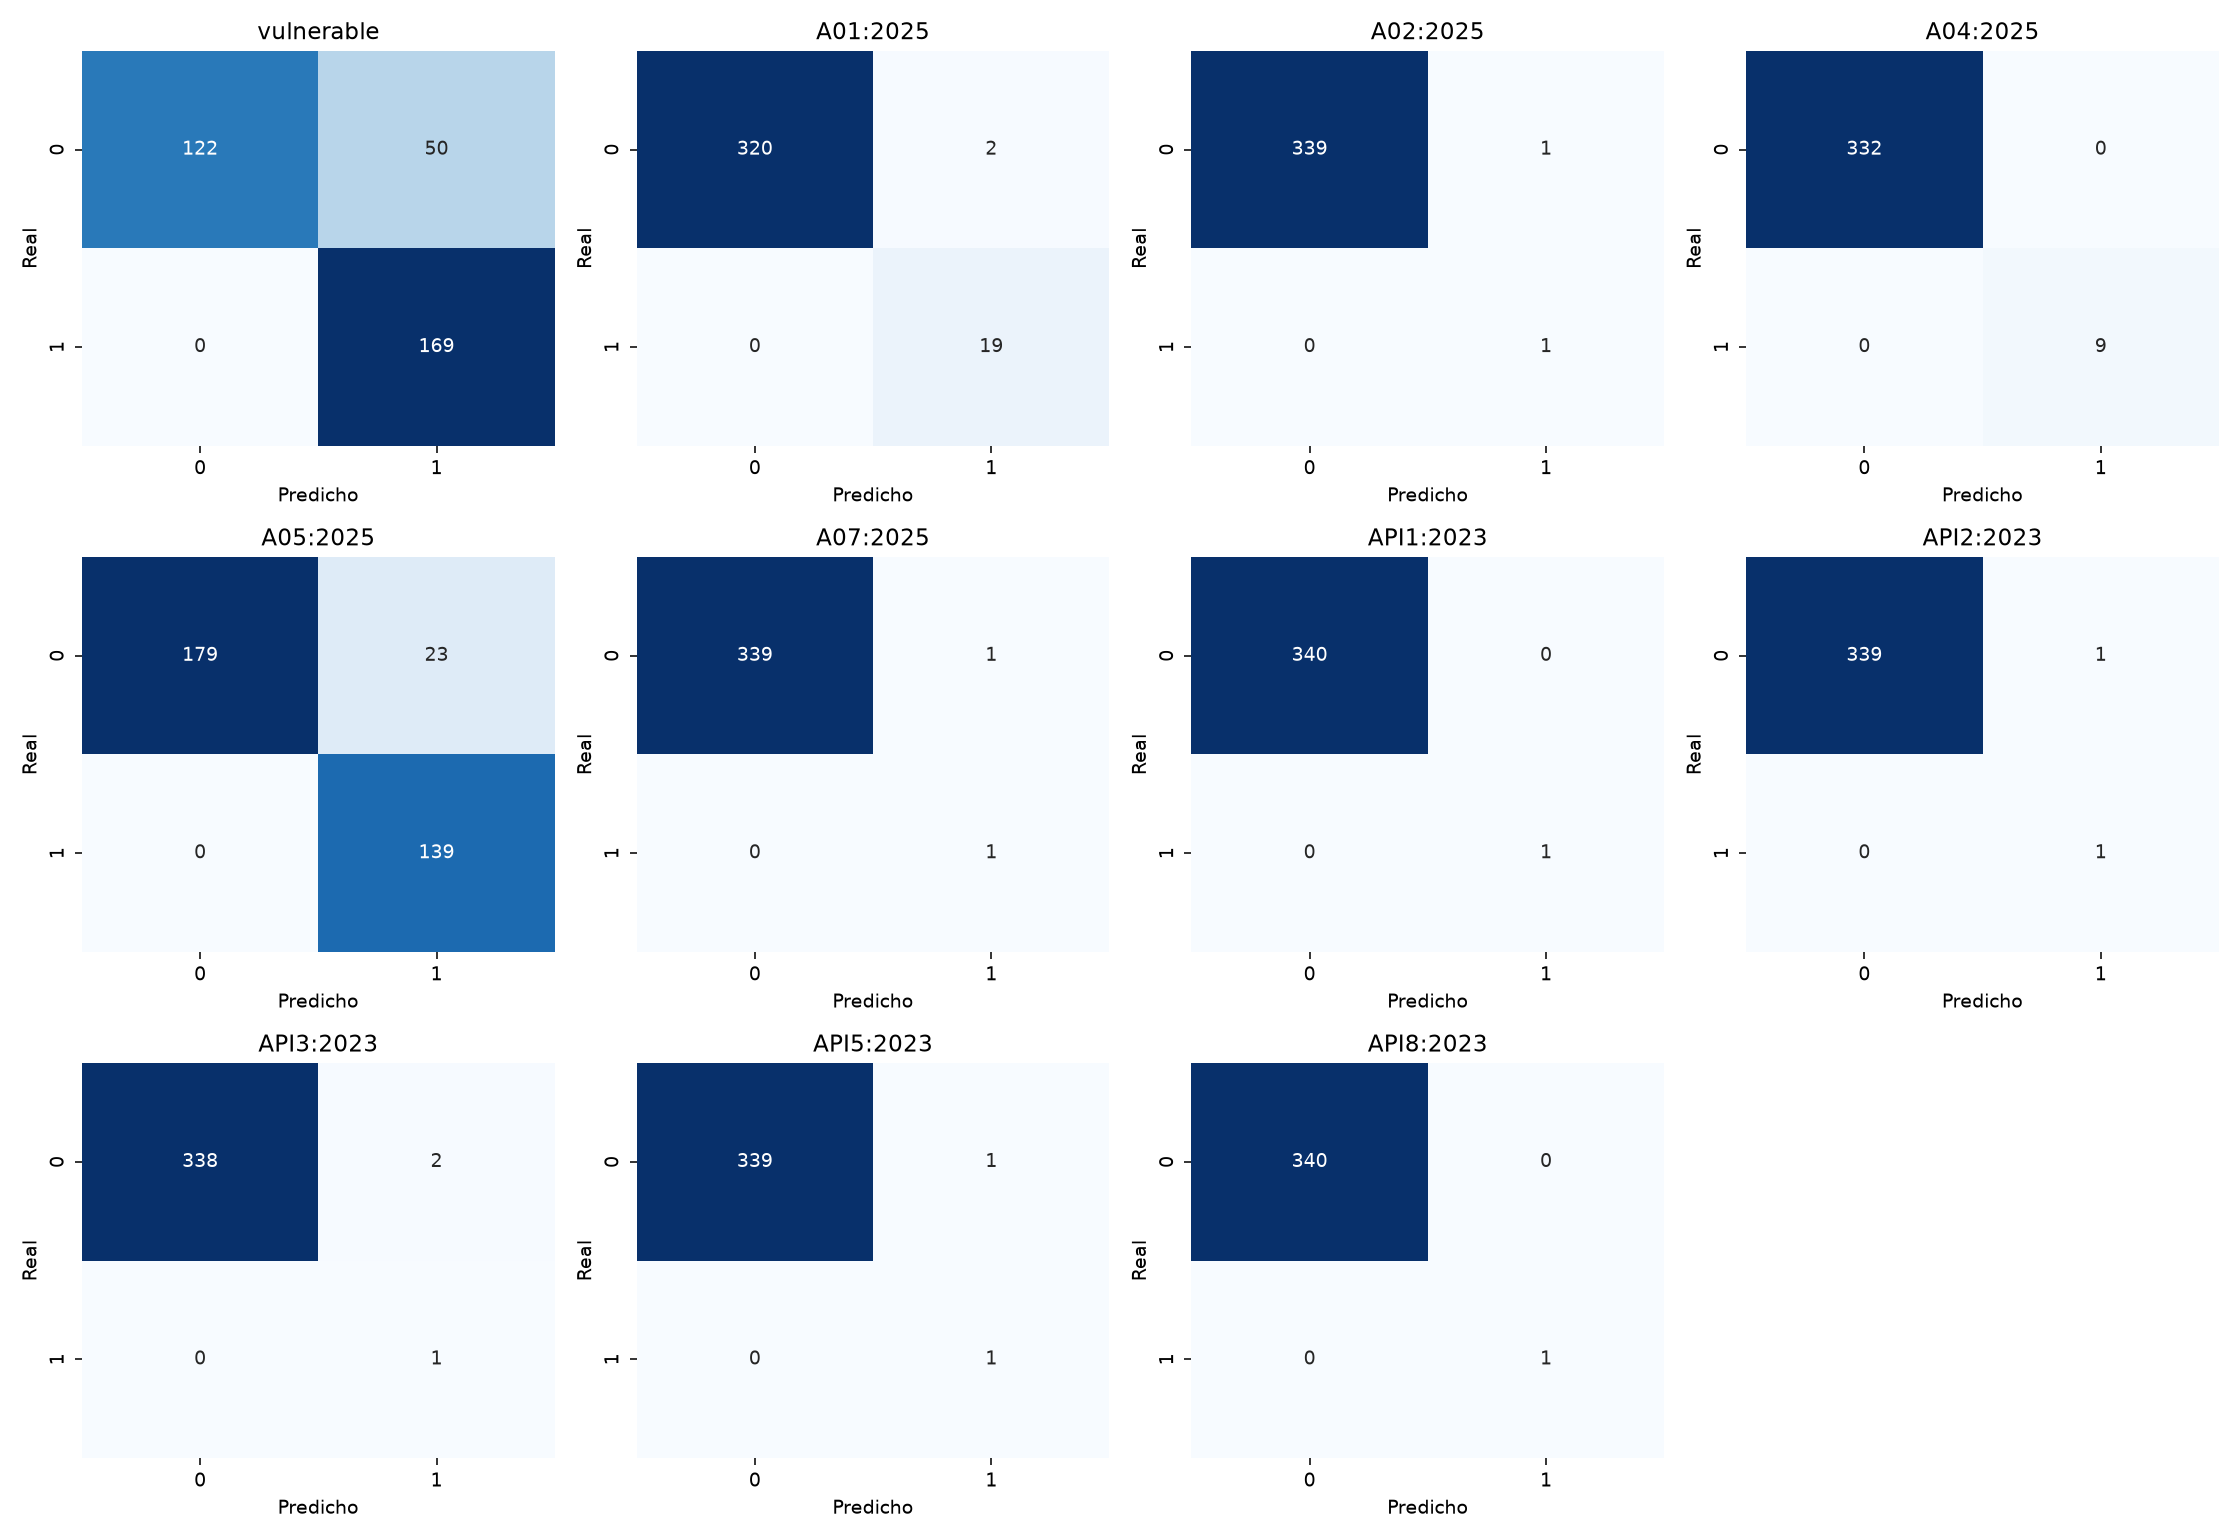

,grouping,group,n,binary_precision,binary_recall,binary_f1,category_precision_macro,category_recall_macro,category_f1_macro,category_f1_micro,hamming_loss,subset_accuracy,f1_macro_supported_labels,supported_labels
0,source,OWASP Benchmark Java 1.2,331,0.784689,1.0,0.879357,0.285802,0.3,0.292359,0.934473,0.006949,0.930514,0.974529,"[""A01:2025"", ""A04:2025"", ""A05:2025""]"
1,source,controlled,10,0.500000,1.0,0.666667,0.493333,0.8,0.591667,0.714286,0.080000,0.400000,0.739583,"[""A01:2025"", ""A02:2025"", ""A07:2025"", ""API1:202..."
2,language,Java,331,0.784689,1.0,0.879357,0.285802,0.3,0.292359,0.934473,0.006949,0.930514,0.974529,"[""A01:2025"", ""A04:2025"", ""A05:2025""]"
3,language,Python,10,0.500000,1.0,0.666667,0.493333,0.8,0.591667,0.714286,0.080000,0.400000,0.739583,"[""A01:2025"", ""A02:2025"", ""A07:2025"", ""API1:202..."


,record_id,source,language,true_labels,true_vulnerable,predicted_labels,predicted_vulnerable,score_vulnerable,status,public_categories,false_positive_labels,false_negative_labels,source_url,diagnosis
0,BenchmarkTest00278,OWASP Benchmark Java 1.2,Java,[],0,"[""A05:2025""]",1,0.456306,hallazgo_potencial,"[""A05:2025""]","[""vulnerable"", ""A05:2025""]",[],https://github.com/OWASP-Benchmark/BenchmarkJa...,"Revisar flujo de datos, guardas y contexto; hi..."
1,BenchmarkTest00283,OWASP Benchmark Java 1.2,Java,[],0,"[""A05:2025""]",1,0.514659,hallazgo_potencial,"[""A05:2025""]","[""vulnerable"", ""A05:2025""]",[],https://github.com/OWASP-Benchmark/BenchmarkJa...,"Revisar flujo de datos, guardas y contexto; hi..."
2,BenchmarkTest00285,OWASP Benchmark Java 1.2,Java,[],0,"[""A05:2025""]",1,0.533488,hallazgo_potencial,"[""A05:2025""]","[""vulnerable"", ""A05:2025""]",[],https://github.com/OWASP-Benchmark/BenchmarkJa...,"Revisar flujo de datos, guardas y contexto; hi..."
3,BenchmarkTest00289,OWASP Benchmark Java 1.2,Java,[],0,"[""A05:2025""]",1,0.513699,hallazgo_potencial,"[""A05:2025""]","[""vulnerable"", ""A05:2025""]",[],https://github.com/OWASP-Benchmark/BenchmarkJa...,"Revisar flujo de datos, guardas y contexto; hi..."
4,BenchmarkTest00406,OWASP Benchmark Java 1.2,Java,[],0,"[""A05:2025""]",1,0.391214,hallazgo_potencial,"[""A05:2025""]","[""vulnerable"", ""A05:2025""]",[],https://github.com/OWASP-Benchmark/BenchmarkJa...,"Revisar flujo de datos, guardas y contexto; hi..."
5,BenchmarkTest00408,OWASP Benchmark Java 1.2,Java,[],0,[],1,0.328348,pendiente_revision,[],"[""vulnerable""]",[],https://github.com/OWASP-Benchmark/BenchmarkJa...,"Revisar flujo de datos, guardas y contexto; hi..."
6,BenchmarkTest00738,OWASP Benchmark Java 1.2,Java,[],0,"[""A05:2025""]",1,0.364010,hallazgo_potencial,"[""A05:2025""]","[""vulnerable"", ""A05:2025""]",[],https://github.com/OWASP-Benchmark/BenchmarkJa...,"Revisar flujo de datos, guardas y contexto; hi..."
7,BenchmarkTest00739,OWASP Benchmark Java 1.2,Java,[],0,[],1,0.348602,pendiente_revision,[],"[""vulnerable""]",[],https://github.com/OWASP-Benchmark/BenchmarkJa...,"Revisar flujo de datos, guardas y contexto; hi..."
8,BenchmarkTest00827,OWASP Benchmark Java 1.2,Java,[],0,[],1,0.311318,pendiente_revision,[],"[""vulnerable""]",[],https://github.com/OWASP-Benchmark/BenchmarkJa...,"Revisar flujo de datos, guardas y contexto; hi..."
9,BenchmarkTest00861,OWASP Benchmark Java 1.2,Java,[],0,[],1,0.334014,pendiente_revision,[],"[""vulnerable""]",[],https://github.com/OWASP-Benchmark/BenchmarkJa...,"Revisar flujo de datos, guardas y contexto; hi..."


Errores con evidencia completa en CSV: 52


In [3]:
display(Image(filename=str(ROOT / f'results/{family}_matrices.png')))
display(pd.read_csv(ROOT / f'results/{family}_por_fuente_lenguaje.csv'))
errors = pd.read_csv(ROOT / f'results/{family}_errores.csv')
display(errors.drop(columns='code').head(10))
print('Errores con evidencia completa en CSV:', len(errors))

## Análisis reproducible y conclusiones

La siguiente celda genera el informe a partir de los resultados y muestra ejemplos concretos de errores; no agrega métricas manualmente.

In [4]:
from src.report import build_report
build_report()
display(Markdown((ROOT / 'docs/informe_semma.md').read_text(encoding='utf-8')))

Report generated from actual saved results.


# Informe técnico del avance SEMMA

## Problema y alcance

Clasificar posibles debilidades en fragmentos de código y configuraciones de servicios,
siguiendo las secciones 7.1–7.5 del PDF `Modelo_mineria_datos.pdf`. El resultado de este
avance es un dataset trazable, análisis exploratorio, un pipeline de características,
dos algoritmos comparados y un modelo serializado evaluado con datos retenidos.
La integración CLI y su demostración sobre un proyecto desconocido quedan pendientes.

La clasificación es binaria y multietiqueta: un fragmento puede asociarse a ambos
estándares. El catálogo contiene las veinte categorías del PDF; diez tienen evidencia
experimental en este dataset y diez están declaradas como no evaluadas.

## Sample — §7.1

Se obtuvieron **2680 fragmentos únicos**, 1313 no vulnerables
a la debilidad objetivo y 1367 vulnerables. Se supera el mínimo del PDF
de 500 registros y 100 ejemplos no vulnerables. Se eliminaron 4
duplicados exactos tras la limpieza; se excluyeron 0
registros con conflicto de etiquetas. No se reutilizó el CSV original de los talleres.

| fuente | registros |
| --- | --- |
| OWASP Benchmark Java 1.2 | 2610 |
| controlled | 70 |

Se usan 2610 casos Java y 70 Python.
Las fuentes, licencias y contratos están en `fuentes.md`; el diccionario y la tabla
CWE–OWASP son entregables separados. Las etiquetas de Benchmark son su resultado esperado,
no una auditoría propia. Los casos controlados necesitan revisión humana.

### Particiones

| partición | no vulnerable objetivo | vulnerable | porcentaje |
| --- | --- | --- | --- |
| test | 172 | 169 | 12.7239 |
| train | 971 | 1030 | 74.6642 |
| validation | 170 | 168 | 12.6119 |

Se mantienen **921 grupos** sin intersección entre particiones. Se agrupan
clones por estructura normalizada y componentes de similitud coseno de caracteres ≥0,90,
sin usar etiquetas para agrupar. Se usa una sola partición por grupos con semillas fijas;
el porcentaje efectivo varía porque no se rompen grupos para forzar 70/15/15.
Este control reduce filtraciones por duplicación; no garantiza independencia semántica.
Benchmark es un solo proyecto, de modo que el test Java mide generalización interna.

## Explore — §7.2

Los gráficos de `results/por_categoria.png`, `por_clase.png`, `por_lenguaje.png`,
`por_fuente.png`, `por_artefacto.png`, `longitudes.png` y `patrones.png` documentan la exploración.
Las tablas correspondientes permiten comprobar recuentos y longitudes. No se encontraron
faltantes en los campos obligatorios después de preparar el conjunto.

El equilibrio aproximado de la etiqueta binaria no implica equilibrio por categoría.
Las etiquetas API tienen siete positivos y siete negativos por escenario en todo el
dataset; solo **un positivo y un negativo de cada escenario** están en test. El dominio
Java y Benchmark domina la muestra. Las categorías agrupan distintas CWE y su frecuencia
no puede interpretarse como prevalencia de riesgos en software real.

Las longitudes son muy diferentes entre funciones Python pequeñas y métodos Java de
servlets. Los tokens frecuentes incluyen sintaxis y bibliotecas; no son por sí mismos
evidencia causal de una vulnerabilidad. Estas diferencias justifican informar resultados
por fuente y lenguaje, además del promedio global.

## Modify — §7.3

Se retiraron comentarios, identificadores de Benchmark y rutas de `doGet` que podían
revelar la etiqueta. Se conservaron literales de código relevantes y helpers de prueba
referidos. Se tokenizan identificadores, números, símbolos y operadores, generando TF-IDF
de unigramas y bigramas con `min_df=2`, `sublinear_tf=True` y máximo 18.000 características.
El vocabulario efectivo es **2686**.

El vectorizador de clasificación se ajustó solo con train; validation y test se transforman
con ese vocabulario congelado. Este vectorizador es distinto al usado para agrupar clones.
Ninguna etiqueta, CWE, ruta de origen o nombre del escenario entra como característica.
Las matrices dispersas y los objetivos se guardan en `data/processed/`.

Se usa `class_weight=balanced` en los problemas binarios One-vs-Rest, sin sobremuestrear
los conjuntos retenidos. El texto permite capturar patrones de consultas, algoritmos,
autenticación y configuraciones, pero no sustituye análisis de flujo ni de dependencias.

## Model — §7.4

Se compararon Regresión Logística (`C=0.5` y `C=2`) y Random Forest (100 árboles sin
límite de profundidad y hoja mínima 2; 150 árboles con profundidad 20 y hoja mínima 1).
Ambos usan One-vs-Rest sobre el objetivo vulnerable y las diez categorías respaldadas.
Se probaron umbrales 0,30, 0,40, 0,50, 0,60 y 0,70 en validación.

Se eligió **rf_150_depth20**, umbral **0.30**, por mayor
F1 macro de categorías en validación: **0.8460**.
F1 binario y tiempo resuelven empates. El modelo se congeló antes de examinar test;
no se reentrenó con validación. La selección no se modifica si otro algoritmo obtiene
una métrica de test mejor. `validation_search.csv` conserva todas las configuraciones.

`models/modelo_seleccionado.joblib` incluye TF-IDF, clasificadores, catálogo y umbral.
Los scores son salidas sin calibrar, no niveles de severidad. Un caso binario positivo
sin categoría suficiente o cercano al umbral queda pendiente de revisión; no se fuerza
una categoría. Las etiquetas emitidas se consideran potenciales y requieren verificación.

## Assess — §7.5

| family | candidate | threshold | train_category_f1_macro | validation_category_f1_macro | test_category_f1_macro | test_binary_precision | test_binary_recall | test_binary_f1 |
| --- | --- | --- | --- | --- | --- | --- | --- | --- |
| random_forest | rf_150_depth20 | 0.3000 | 0.8884 | 0.8460 | 0.8040 | 0.7717 | 1.0000 | 0.8711 |
| logistic_regression | lr_C2 | 0.5000 | 0.8385 | 0.6255 | 0.6391 | 0.8674 | 0.9290 | 0.8971 |

En test, el modelo seleccionado obtuvo F1 binario **0.8711** y F1 macro
de categorías **0.8040**. El promedio macro corresponde a las
diez categorías con datos, **no a todo el catálogo de veinte**. Las categorías no evaluadas
no se incorporan como ceros artificiales ni se presentan como cobertura conseguida.
También se exportan F1 micro, precision/recall macro, Hamming loss y exactitud de conjuntos.

La diferencia train–validación del F1 macro es
**0.0425**. Esta diferencia y
el resultado de test ayudan a examinar el sobreajuste, pero no permiten descartarlo en
otros proyectos. En cada etiqueta, la matriz 2×2 usa filas reales y columnas predichas:
`[[TN, FP], [FN, TP]]`. El gating y la abstención de categorías forman parte de la evaluación;
el objetivo binario conserva su decisión por umbral aun cuando el estado sea pendiente.

### Métricas por categoría

| categoria | precision | recall | f1-score | support |
| --- | --- | --- | --- | --- |
| A01:2025 | 0.9048 | 1.0000 | 0.9500 | 19.0000 |
| A02:2025 | 0.5000 | 1.0000 | 0.6667 | 1.0000 |
| A04:2025 | 1.0000 | 1.0000 | 1.0000 | 9.0000 |
| A05:2025 | 0.8580 | 1.0000 | 0.9236 | 139.0000 |
| A07:2025 | 0.5000 | 1.0000 | 0.6667 | 1.0000 |
| API1:2023 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |
| API2:2023 | 0.5000 | 1.0000 | 0.6667 | 1.0000 |
| API3:2023 | 0.3333 | 1.0000 | 0.5000 | 1.0000 |
| API5:2023 | 0.5000 | 1.0000 | 0.6667 | 1.0000 |
| API8:2023 | 1.0000 | 1.0000 | 1.0000 | 1.0000 |

### Resultados por fuente y lenguaje

| grouping | group | n | binary_precision | binary_recall | binary_f1 | f1_macro_supported_labels |
| --- | --- | --- | --- | --- | --- | --- |
| source | OWASP Benchmark Java 1.2 | 331 | 0.7847 | 1.0000 | 0.8794 | 0.9745 |
| source | controlled | 10 | 0.5000 | 1.0000 | 0.6667 | 0.7396 |
| language | Java | 331 | 0.7847 | 1.0000 | 0.8794 | 0.9745 |
| language | Python | 10 | 0.5000 | 1.0000 | 0.6667 | 0.7396 |

En este desglose, `f1_macro_supported_labels` promedia únicamente etiquetas con positivos
en el subconjunto; los CSV conservan también el macro sobre el conjunto fijo de etiquetas
para que ambos promedios sean auditables. No se deben comparar promedios con distinto
conjunto de etiquetas sin considerar ese detalle.

### Falsos positivos, falsos negativos y abstenciones

Se observaron **50 falsos positivos binarios** y **0 falsos negativos binarios**.
Hay **52 registros con al menos un error binario o de categoría** y
**29 registros con estado pendiente de revisión**. Los CSV `*_errores.csv` incluyen
el fragmento completo, etiquetas, procedencia y la necesidad de revisión. Los CSV de
predicciones permiten reconstruir las métricas. No observar un falso negativo en una
muestra no demuestra que el detector no pueda omitir vulnerabilidades.

### Caso BenchmarkTest00278

Fuente: OWASP Benchmark Java 1.2. Real binario: 0; predicho: 1. FP de etiquetas: `["vulnerable", "A05:2025"]`; FN: `[]`.

```java
public void doPost(HttpServletRequest request, HttpServletResponse response)
            throws ServletException, IOException {
        response.setContentType("text/html;charset=UTF-8");
        String param = "";
        java.util.Enumeration<String> headers = request.getHeaders("Referer");
        if (headers != null && headers.hasMoreElements()) {
            param = headers.nextElement();
        }
        param = java.net.URLDecoder.decode(param, "UTF-8");
        String bar = org.springframework.web.util.HtmlUtils.htmlEscape(param);
        response.setHeader("X-XSS-Protection", "0");
        response.getWriter().print(bar);
    }
}
```

Hipótesis: el vocabulario de la operación peligrosa pesa más que la mitigación o la ruta de datos efectiva. La etiqueta de Benchmark corresponde únicamente a la CWE objetivo.

Procedencia: https://github.com/OWASP-Benchmark/BenchmarkJava/blob/10dfcc54ad02dcfcb358b0ba4a0fef8c919a6d17/src/main/java/org/owasp/benchmark/testcode/BenchmarkTest00278.java
### Caso control-object_authorization-6-1

Fuente: controlled. Real binario: 1; predicho: 1. FP de etiquetas: `["API5:2023"]`; FN: `[]`.

```python
def get_ticket(ticket_id, user):
    ticket = tickets.fetch(ticket_id)
    return ticket.details
```

Hipótesis: hay poco soporte de entrenamiento para este escenario y la representación textual no modela de forma fiable las guardas, propiedades permitidas ni contratos externos.

Procedencia: src/controlled.py
### Caso control-object_authorization-6-0

Fuente: controlled. Real binario: 0; predicho: 1. FP de etiquetas: `["vulnerable", "A01:2025"]`; FN: `[]`.

```python
def get_ticket(ticket_id, user):
    ticket = tickets.fetch(ticket_id)
    if ticket.tenant_id != user.tenant_id:
        raise PermissionError()
    return ticket.details
```

Hipótesis: hay poco soporte de entrenamiento para este escenario y la representación textual no modela de forma fiable las guardas, propiedades permitidas ni contratos externos.

Procedencia: src/controlled.py

## Limitaciones y mejoras

1. Los ejemplos API son pocos y controlados. Un caso adicional puede cambiar mucho el
   recall de una categoría. Ampliar fuentes, revisar etiquetas y evaluar proyectos externos
   antes de afirmar detección confiable de autorización o autenticación.
2. Benchmark y los casos controlados no reflejan la diversidad de microservicios reales.
   Separar por repositorios independientes y añadir contextos interprocedimentales es la
   siguiente evaluación necesaria; no se infiere generalización a partir de este test.
3. TF-IDF aprende correlaciones textuales. Puede confundir una llamada peligrosa con una
   vulnerabilidad o ignorar validaciones; agregar características sintácticas y de flujo como
   complemento, conservando la contribución del modelo entrenado.
4. Los scores no están calibrados y el umbral se ajustó con pocos casos API. Ampliar la
   validación, estudiar calibración y analizar compromisos precision–recall sin ajustar test.
5. Categorías no evaluadas: A03:2025, A06:2025, A08:2025, A09:2025, A10:2025, API4:2023, API6:2023, API7:2023, API9:2023, API10:2023. Su ausencia de hallazgos nunca equivale a
   ausencia de vulnerabilidades.

## Entregables y pendiente de integración

El avance entrega dataset, diccionario, fuentes, correspondencias CWE–OWASP, cinco
notebooks ejecutables, matrices, entrenamiento reproducible, comparación experimental,
modelos serializados y evaluación con evidencia de errores. La actividad 7 de Assess
(pruebas funcionales sobre microservicios desconocidos) y la sección 8 (CLI, descubrimiento,
líneas y reportes JSON/HTML de seguridad) continúan pendientes. Los JSON de métricas de
este avance no se presentan como reportes de hallazgos de una CLI.

El resultado respalda una base experimental para integrar un detector de hallazgos
potenciales. La validación disponible no respalda desplegarlo como certificador de seguridad.


## Actividad pendiente del PDF

La actividad 7 de Assess (pruebas funcionales en proyectos de microservicios desconocidos) se realizará al integrar la CLI. Evaluar fragmentos retenidos no la sustituye. Tampoco se ha probado generalización a repositorios reales externos ni confirmado vulnerabilidades mediante pruebas dinámicas.